In [7]:
import os
import re
import shutil
import random
from pathlib import Path
from collections import Counter, defaultdict

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [8]:
INPUT_DIR = Path("/kaggle/input")

print("Datasets available in Kaggle:\n")

for p in INPUT_DIR.iterdir():
    print(p)

Datasets available in Kaggle:

/kaggle/input/datasets


In [9]:
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".JPG", ".JPEG", ".PNG"
}

images = [
    p for p in INPUT_DIR.rglob("*")
    if p.is_file() and p.suffix in IMAGE_EXTENSIONS
]

print("Total images found:", len(images))

print("\nFirst 20 images:")
for img in images[:20]:
    print(img)

Total images found: 16488

First 20 images:
/kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Tomas Milian/3909_TomasMilian_72_m.jpg
/kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Tomas Milian/3908_TomasMilian_71_m.jpg
/kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Tomas Milian/3910_TomasMilian_74_m.jpg
/kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Tomas Milian/3902_TomasMilian_43_m.jpg
/kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Tomas Milian/3890_TomasMilian_30_m.jpg
/kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Tomas Milian/3891_TomasMilian_31_m.jpg
/kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Tomas Milian/3904_TomasMilian_53_m.jpg
/kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Tomas Milian/3916_TomasMilian_80_m.jpg
/kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Tomas Milian/3907_TomasMilian_64_m.jpg
/kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Tomas

In [10]:
folder_counts = Counter(img.parent for img in images)

print("Number of folders:", len(folder_counts))
print()

for folder, count in folder_counts.most_common(30):
    print(f"{count:4d} images -> {folder}")

Number of folders: 567

  78 images -> /kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Tom Jones
  60 images -> /kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Luise Rainer
  59 images -> /kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Jeanette Mac Donald
  58 images -> /kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Gladys Cooper
  54 images -> /kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Roy Scheider
  52 images -> /kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Jane Powell
  52 images -> /kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Danielle Darrieux
  51 images -> /kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Roman Polanski
  51 images -> /kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Michel Piccoli
  51 images -> /kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Angie Dickinson
  50 images -> /kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset/Myrna

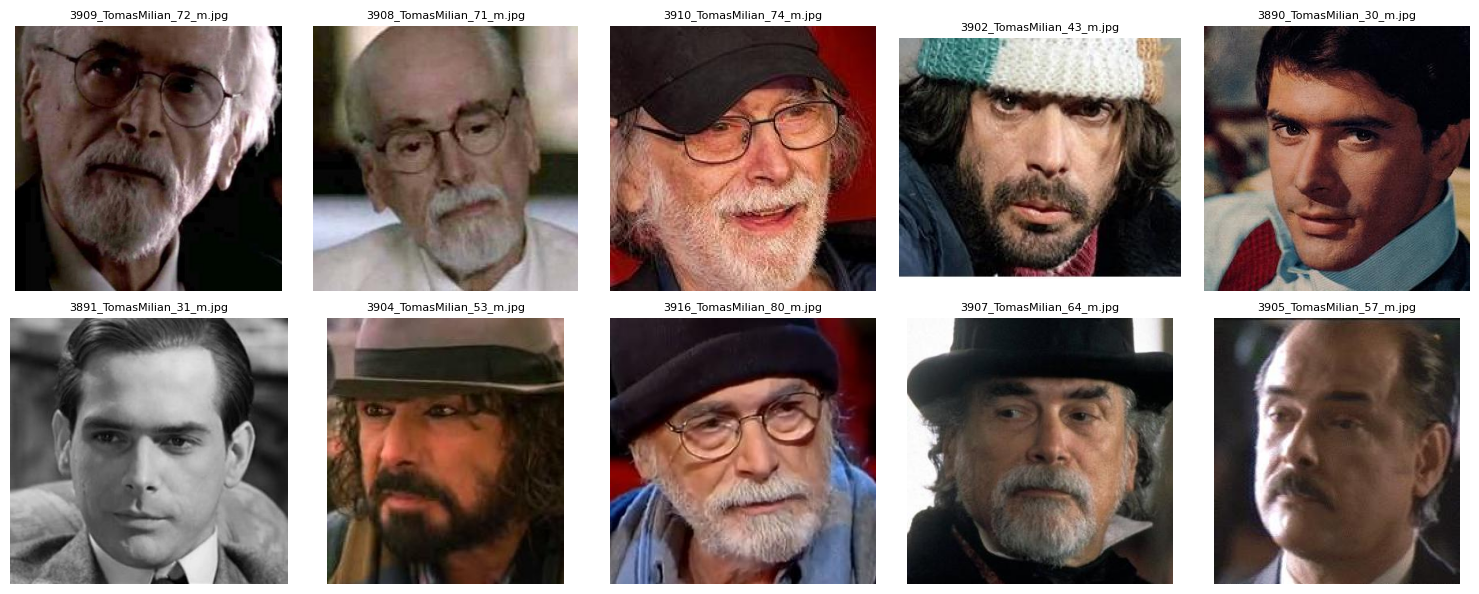

In [11]:
sample_images = images[:10]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, img_path in zip(axes.ravel(), sample_images):
    try:
        img = Image.open(img_path).convert("RGB")
        ax.imshow(img)
        ax.set_title(img_path.name, fontsize=8)
    except:
        ax.set_title("Could not open")

    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
from pathlib import Path
import pandas as pd
import re

DATASET_DIR = Path(
    "/kaggle/input/datasets/shukdevdatta/agedb-classwise-dataset"
)

images = list(DATASET_DIR.rglob("*.jpg"))

print("Total images:", len(images))
print("Total identity folders:", len([
    p for p in DATASET_DIR.iterdir()
    if p.is_dir()
]))

Total images: 16488
Total identity folders: 567


In [13]:
records = []

for img_path in images:

    # Identity comes from folder name
    identity = img_path.parent.name

    # Filename:
    # ID_Name_Age_Gender.jpg
    #
    # Example:
    # 3909_TomasMilian_72_m.jpg

    parts = img_path.stem.split("_")

    try:
        age = int(parts[-2])
        gender = parts[-1].lower()
    except:
        continue

    records.append({
        "path": str(img_path),
        "filename": img_path.name,
        "identity": identity,
        "age": age,
        "gender": gender
    })

df = pd.DataFrame(records)

print("Parsed images:", len(df))
print("Identities:", df["identity"].nunique())

print("\nFirst 10 records:")
display(df.head(10))

Parsed images: 16488
Identities: 567

First 10 records:


,path,filename,identity,age,gender
0,/kaggle/input/datasets/shukdevdatta/agedb-clas...,3909_TomasMilian_72_m.jpg,Tomas Milian,72,m
1,/kaggle/input/datasets/shukdevdatta/agedb-clas...,3908_TomasMilian_71_m.jpg,Tomas Milian,71,m
2,/kaggle/input/datasets/shukdevdatta/agedb-clas...,3910_TomasMilian_74_m.jpg,Tomas Milian,74,m
3,/kaggle/input/datasets/shukdevdatta/agedb-clas...,3902_TomasMilian_43_m.jpg,Tomas Milian,43,m
4,/kaggle/input/datasets/shukdevdatta/agedb-clas...,3890_TomasMilian_30_m.jpg,Tomas Milian,30,m
5,/kaggle/input/datasets/shukdevdatta/agedb-clas...,3891_TomasMilian_31_m.jpg,Tomas Milian,31,m
6,/kaggle/input/datasets/shukdevdatta/agedb-clas...,3904_TomasMilian_53_m.jpg,Tomas Milian,53,m
7,/kaggle/input/datasets/shukdevdatta/agedb-clas...,3916_TomasMilian_80_m.jpg,Tomas Milian,80,m
8,/kaggle/input/datasets/shukdevdatta/agedb-clas...,3907_TomasMilian_64_m.jpg,Tomas Milian,64,m
9,/kaggle/input/datasets/shukdevdatta/agedb-clas...,3905_TomasMilian_57_m.jpg,Tomas Milian,57,m


In [14]:
print("=== DATASET SUMMARY ===")

print("Images:", len(df))
print("Identities:", df["identity"].nunique())

print("\nGender distribution:")
print(df["gender"].value_counts())

print("\nAge statistics:")
print(df["age"].describe())

print("\nAge range:")
print(
    df["age"].min(),
    "to",
    df["age"].max()
)

=== DATASET SUMMARY ===
Images: 16488
Identities: 567

Gender distribution:
gender
m    9788
f    6700
Name: count, dtype: int64

Age statistics:
count    16488.000000
mean        46.261220
std         17.438963
min          1.000000
25%         32.000000
50%         44.000000
75%         59.000000
max        101.000000
Name: age, dtype: float64

Age range:
1 to 101


In [15]:
identity_counts = (
    df.groupby("identity")
      .size()
      .sort_values(ascending=False)
)

print(
    "Identities with >= 2 images:",
    (identity_counts >= 2).sum()
)

print("\nImages per identity:")
display(identity_counts.describe())

Identities with >= 2 images: 566

Images per identity:


count    567.000000
mean      29.079365
std        9.502411
min        1.000000
25%       23.000000
50%       29.000000
75%       35.000000
max       78.000000
dtype: float64

In [16]:
valid_identities = identity_counts[
    identity_counts >= 2
].index

candidate_df = df[
    df["identity"].isin(valid_identities)
].copy()

print("Candidate images:", len(candidate_df))
print(
    "Candidate identities:",
    candidate_df["identity"].nunique()
)

Candidate images: 16487
Candidate identities: 566


In [17]:
# Age-gap controlled pair selection
PREFERRED_MIN_AGE = 5
MAX_AGE_GAP = 9  # Keep age gap strictly below 10 years if possible

def select_best_pair(group):
    # Prefer images where both ages are >= 5
    preferred = group[group["age"] >= PREFERRED_MIN_AGE].copy()
    candidates = preferred if len(preferred) >= 2 else group.copy()

    if len(candidates) < 2:
        return None

    candidates = candidates.sort_values("age").reset_index(drop=True)

    # First try to find the largest possible age gap that is still < 10 years.
    valid_pairs = []
    for i in range(len(candidates)):
        for j in range(i + 1, len(candidates)):
            gap = abs(candidates.loc[j, "age"] - candidates.loc[i, "age"])
            if gap <= MAX_AGE_GAP:
                valid_pairs.append((gap, i, j))

    if valid_pairs:
        # Prefer the largest controlled gap, not an unnecessarily tiny gap.
        gap, i, j = max(valid_pairs, key=lambda x: x[0])
    else:
        # Fallback: if this identity has no pair below 10 years, use its
        # closest available pair rather than creating a large age gap.
        closest = []
        for i in range(len(candidates)):
            for j in range(i + 1, len(candidates)):
                gap = abs(candidates.loc[j, "age"] - candidates.loc[i, "age"])
                closest.append((gap, i, j))
        gap, i, j = min(closest, key=lambda x: x[0])

    img1 = candidates.loc[i]
    img2 = candidates.loc[j]

    return {
        "identity": group["identity"].iloc[0],
        "image1": img1["path"],
        "image2": img2["path"],
        "age1": int(img1["age"]),
        "age2": int(img2["age"]),
        "gender": img1["gender"],
        "age_gap": int(gap),
    }


pairs = []
for identity, group in candidate_df.groupby("identity"):
    result = select_best_pair(group)
    if result is not None:
        pairs.append(result)

pairs_df = pd.DataFrame(pairs).sort_values("age_gap", ascending=False).reset_index(drop=True)

print("Candidate identities with a selected pair:", len(pairs_df))
print("Age-gap distribution:")
print(pairs_df["age_gap"].describe())
print("\nPairs with age gap < 10:", (pairs_df["age_gap"] < 10).sum())
print("Pairs with age gap >= 10:", (pairs_df["age_gap"] >= 10).sum())


Candidate identities with a selected pair: 566
Age-gap distribution:
count    566.000000
mean       8.932862
std        0.397890
min        4.000000
25%        9.000000
50%        9.000000
75%        9.000000
max        9.000000
Name: age_gap, dtype: float64

Pairs with age gap < 10: 566
Pairs with age gap >= 10: 0


In [18]:
NUM_SUBJECTS = 200

# Because pairs_df prioritizes age gaps <= 9, the first 200 subjects
# will normally satisfy the requested controlled age-gap condition.
# If fewer than 200 such pairs exist, use the closest-gap fallback pairs.
controlled = pairs_df[pairs_df["age_gap"] < 10].copy()

if len(controlled) >= NUM_SUBJECTS:
    selected = controlled.head(NUM_SUBJECTS).copy()
else:
    print(f"Only {len(controlled)} subjects have age gap < 10.")
    print("Using additional closest available pairs to reach 200 subjects.")
    selected = pairs_df.head(NUM_SUBJECTS).copy()

if len(selected) < NUM_SUBJECTS:
    raise ValueError(
        f"Only {len(selected)} subjects available. Need at least {NUM_SUBJECTS}."
    )

selected = selected.head(NUM_SUBJECTS).copy()
selected.insert(
    0,
    "subject_id",
    [f"subject_{i:03d}" for i in range(1, NUM_SUBJECTS + 1)]
)

print("Selected subjects:", len(selected))
print("Selected images:", len(selected) * 2)
print("Maximum selected age gap:", selected["age_gap"].max())
print("Average selected age gap:", round(selected["age_gap"].mean(), 2))
print("Pairs with age gap < 10:", (selected["age_gap"] < 10).sum(), "/", NUM_SUBJECTS)


Selected subjects: 200
Selected images: 400
Maximum selected age gap: 9
Average selected age gap: 9.0
Pairs with age gap < 10: 200 / 200


In [19]:
print("Gender distribution of selected subjects:")

print(
    selected["gender"]
    .value_counts()
)

print("\nPercentage:")

print(
    selected["gender"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Gender distribution of selected subjects:
gender
m    116
f     84
Name: count, dtype: int64

Percentage:
gender
m    58.0
f    42.0
Name: proportion, dtype: float64


In [20]:
ages = pd.concat([
    selected[["subject_id", "age1"]]
    .rename(columns={"age1": "age"}),

    selected[["subject_id", "age2"]]
    .rename(columns={"age2": "age"})
])

print("Minimum age:", ages["age"].min())
print("Maximum age:", ages["age"].max())
print("Average age:", round(ages["age"].mean(), 2))

Minimum age: 7
Maximum age: 89
Average age: 31.12


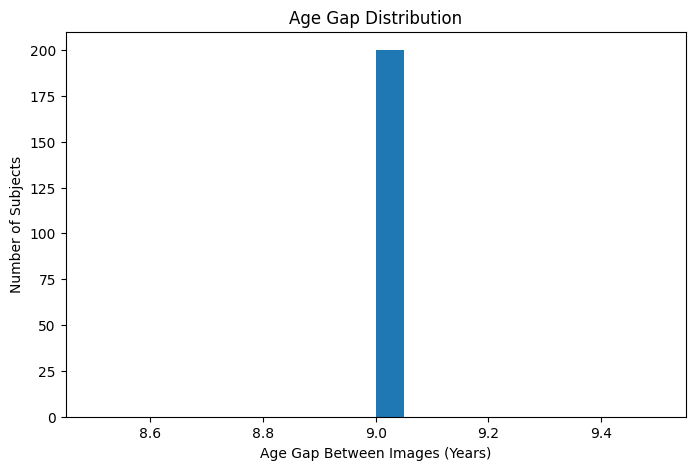

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    selected["age_gap"],
    bins=20
)

plt.xlabel(
    "Age Gap Between Images (Years)"
)

plt.ylabel(
    "Number of Subjects"
)

plt.title(
    "Age Gap Distribution"
)

plt.show()

In [22]:
import shutil

OUTPUT_DIR = Path(
    "/kaggle/working/AgeDB_Assignment2"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

final_records = []

for _, row in selected.iterrows():

    subject_id = row["subject_id"]

    subject_dir = (
        OUTPUT_DIR / subject_id
    )

    subject_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # -------------------------
    # IMAGE 1
    # -------------------------

    source1 = Path(
        row["image1"]
    )

    destination1 = (
        subject_dir /
        f"{subject_id}_img1_age{row['age1']}.jpg"
    )

    shutil.copy2(
        source1,
        destination1
    )

    # -------------------------
    # IMAGE 2
    # -------------------------

    source2 = Path(
        row["image2"]
    )

    destination2 = (
        subject_dir /
        f"{subject_id}_img2_age{row['age2']}.jpg"
    )

    shutil.copy2(
        source2,
        destination2
    )

    final_records.append({
        "subject_id": subject_id,
        "image_number": 1,
        "age": row["age1"],
        "age_gap": row["age_gap"],
        "gender": row["gender"],
        "original_identity": row["identity"],
        "original_path": str(source1),
        "new_path": str(destination1)
    })

    final_records.append({
        "subject_id": subject_id,
        "image_number": 2,
        "age": row["age2"],
        "age_gap": row["age_gap"],
        "gender": row["gender"],
        "original_identity": row["identity"],
        "original_path": str(source2),
        "new_path": str(destination2)
    })


final_metadata = pd.DataFrame(
    final_records
)

print(
    "Created images:",
    len(final_metadata)
)

Created images: 400


In [23]:
metadata_path = (
    OUTPUT_DIR / "metadata.csv"
)

final_metadata.to_csv(
    metadata_path,
    index=False
)

print(
    "Metadata saved at:"
)

print(metadata_path)

display(
    final_metadata.head(10)
)

Metadata saved at:
/kaggle/working/AgeDB_Assignment2/metadata.csv


,subject_id,image_number,age,age_gap,gender,original_identity,original_path,new_path
0,subject_001,1,33,9,m,tomselleck,/kaggle/input/datasets/shukdevdatta/agedb-clas...,/kaggle/working/AgeDB_Assignment2/subject_001/...
1,subject_001,2,42,9,m,tomselleck,/kaggle/input/datasets/shukdevdatta/agedb-clas...,/kaggle/working/AgeDB_Assignment2/subject_001/...
2,subject_002,1,49,9,m,Abe Vigoda,/kaggle/input/datasets/shukdevdatta/agedb-clas...,/kaggle/working/AgeDB_Assignment2/subject_002/...
3,subject_002,2,58,9,m,Abe Vigoda,/kaggle/input/datasets/shukdevdatta/agedb-clas...,/kaggle/working/AgeDB_Assignment2/subject_002/...
4,subject_003,1,43,9,m,Adolf Hitlerr,/kaggle/input/datasets/shukdevdatta/agedb-clas...,/kaggle/working/AgeDB_Assignment2/subject_003/...
5,subject_003,2,52,9,m,Adolf Hitlerr,/kaggle/input/datasets/shukdevdatta/agedb-clas...,/kaggle/working/AgeDB_Assignment2/subject_003/...
6,subject_004,1,20,9,m,Al Corley,/kaggle/input/datasets/shukdevdatta/agedb-clas...,/kaggle/working/AgeDB_Assignment2/subject_004/...
7,subject_004,2,29,9,m,Al Corley,/kaggle/input/datasets/shukdevdatta/agedb-clas...,/kaggle/working/AgeDB_Assignment2/subject_004/...
8,subject_005,1,23,9,m,Al Kapone,/kaggle/input/datasets/shukdevdatta/agedb-clas...,/kaggle/working/AgeDB_Assignment2/subject_005/...
9,subject_005,2,32,9,m,Al Kapone,/kaggle/input/datasets/shukdevdatta/agedb-clas...,/kaggle/working/AgeDB_Assignment2/subject_005/...


In [24]:
subject_counts = (
    final_metadata
    .groupby("subject_id")
    .size()
)

print("=" * 60)
print("FINAL DATASET VALIDATION")
print("=" * 60)

print(
    "Subjects:",
    len(subject_counts)
)

print(
    "Images:",
    len(final_metadata)
)

print(
    "Minimum images per subject:",
    subject_counts.min()
)

print(
    "Maximum images per subject:",
    subject_counts.max()
)

print(
    "Minimum age:",
    final_metadata["age"].min()
)

print(
    "Maximum age:",
    final_metadata["age"].max()
)

print(
    "Average age:",
    round(
        final_metadata["age"].mean(),
        2
    )
)

print(
    "Average age gap:",
    round(
        final_metadata
        .groupby("subject_id")["age_gap"]
        .first()
        .mean(),
        2
    )
)

print("\nGender:")
print(
    final_metadata
    .groupby("subject_id")["gender"]
    .first()
    .value_counts()
)

assert len(subject_counts) >= 200
assert subject_counts.min() >= 2

print(
    "\n✓ ALL BASIC REQUIREMENTS PASSED"
)

FINAL DATASET VALIDATION
Subjects: 200
Images: 400
Minimum images per subject: 2
Maximum images per subject: 2
Minimum age: 7
Maximum age: 89
Average age: 31.12
Average age gap: 9.0

Gender:
gender
m    116
f     84
Name: count, dtype: int64

✓ ALL BASIC REQUIREMENTS PASSED



subject_001 | Age gap = 9 years
Age: 33


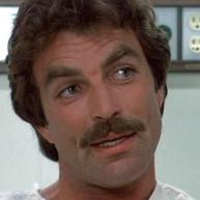

Age: 42


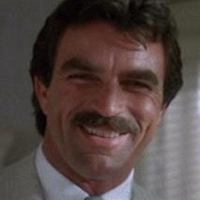


subject_002 | Age gap = 9 years
Age: 49


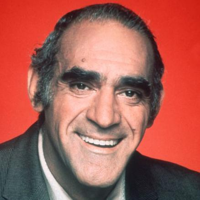

Age: 58


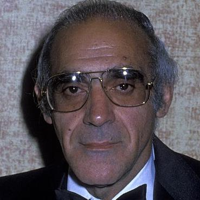


subject_003 | Age gap = 9 years
Age: 43


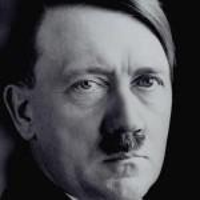

Age: 52


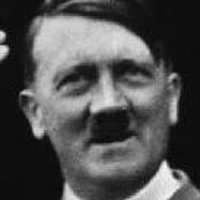


subject_004 | Age gap = 9 years
Age: 20


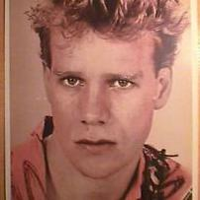

Age: 29


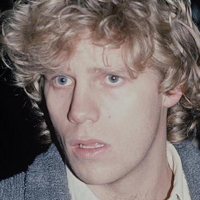


subject_005 | Age gap = 9 years
Age: 23


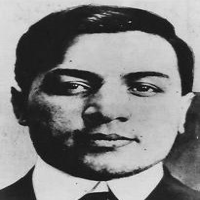

Age: 32


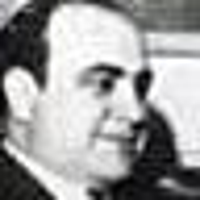

In [25]:
from IPython.display import display

example_subjects = (
    final_metadata["subject_id"]
    .drop_duplicates()
    .head(5)
)

for subject_id in example_subjects:

    rows = final_metadata[
        final_metadata["subject_id"]
        == subject_id
    ].sort_values("image_number")

    print(
        f"\n{subject_id} | "
        f"Age gap = "
        f"{rows['age_gap'].iloc[0]:.0f} years"
    )

    for _, row in rows.iterrows():

        print(
            f"Age: {row['age']:.0f}"
        )

        img = Image.open(
            row["new_path"]
        )

        display(
            img.resize((200, 200))
        )

In [26]:
zip_path = shutil.make_archive(
    "/kaggle/working/AgeDB_Assignment2",
    "zip",
    OUTPUT_DIR
)

print(
    "ZIP created:"
)

print(zip_path)

ZIP created:
/kaggle/working/AgeDB_Assignment2.zip


In [27]:
print("Final dataset location:")
print(OUTPUT_DIR)

print("\nFiles:")

for path in sorted(
    OUTPUT_DIR.rglob("*")
)[:30]:

    print(path)

Final dataset location:
/kaggle/working/AgeDB_Assignment2

Files:
/kaggle/working/AgeDB_Assignment2/metadata.csv
/kaggle/working/AgeDB_Assignment2/subject_001
/kaggle/working/AgeDB_Assignment2/subject_001/subject_001_img1_age33.jpg
/kaggle/working/AgeDB_Assignment2/subject_001/subject_001_img2_age42.jpg
/kaggle/working/AgeDB_Assignment2/subject_002
/kaggle/working/AgeDB_Assignment2/subject_002/subject_002_img1_age49.jpg
/kaggle/working/AgeDB_Assignment2/subject_002/subject_002_img2_age58.jpg
/kaggle/working/AgeDB_Assignment2/subject_003
/kaggle/working/AgeDB_Assignment2/subject_003/subject_003_img1_age43.jpg
/kaggle/working/AgeDB_Assignment2/subject_003/subject_003_img2_age52.jpg
/kaggle/working/AgeDB_Assignment2/subject_004
/kaggle/working/AgeDB_Assignment2/subject_004/subject_004_img1_age20.jpg
/kaggle/working/AgeDB_Assignment2/subject_004/subject_004_img2_age29.jpg
/kaggle/working/AgeDB_Assignment2/subject_005
/kaggle/working/AgeDB_Assignment2/subject_005/subject_005_img1_age23.jpg
